# Sentiment Analysis of X (Twitter) Conversations Using VADER NLP

**ShadowFox Data Science Internship — Task 2 (Intermediate Level)**  
**Author**: Data Science Intern  
**Domain**: Natural Language Processing (NLP) & Social Media Analytics  
**Methodology**: VADER (Valence Aware Dictionary and sEntiment Reasoner)  

---

### Project Objectives & Research Scope
Public discourse on social media platforms like X (formerly Twitter) is characterized by fast-paced discussions, emotional polarity, and viral information diffusion. This project undertakes a rigorous, end-to-end sentiment analysis pipeline to evaluate prevailing sentiment distributions, temporal volatility, topic-specific polarity, and user engagement dynamics.

### Key Research Questions (RQs):
1. **RQ1 (Sentiment Distribution)**: What is the macro-level distribution of positive, negative, and neutral sentiment across platform discourse?
2. **RQ2 (Domain Variation)**: How does sentiment skew across specific topics (*Tech & AI, Economy & Markets, Gaming, Entertainment, Climate & Energy*)? Which topics harbor the highest toxicity or enthusiasm?
3. **RQ3 (Temporal Dynamics)**: How does sentiment compound score fluctuate over daily and weekly cycles?
4. **RQ4 (Virality & Engagement)**: Are polarizing or negative posts associated with higher user engagement (retweets, replies, likes)?
5. **RQ5 (Lexical Patterns)**: What dominant keywords and linguistic tokens distinguish positive vs. negative sentiment clusters?


In [1]:
import os
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Aesthetic configurations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("Environment initialized with Pandas, NumPy, Seaborn, Matplotlib, and VADER.")


Environment initialized with Pandas, NumPy, Seaborn, Matplotlib, and VADER.


## 1. Data Ingestion & Exploratory Schema Audit

We load the curated dataset containing 1,200 timestamped records across 5 discussion categories on X.


In [2]:
# Load the dataset
data_path = os.path.join("data", "x_tweets_sentiment_dataset.csv")
df = pd.read_csv(data_path)

# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['date'] = df['timestamp'].dt.date
df['hour'] = df['timestamp'].dt.hour
df['day_name'] = df['timestamp'].dt.day_name()

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)


Dataset Shape: 1200 rows, 17 columns


,tweet_id,timestamp,topic,user_handle,raw_tweet,retweets,likes,replies,cleaned_text,neg_score,neu_score,pos_score,compound_score,sentiment,date,hour,day_name
0,TWT_100989,2026-08-01 08:09:00,Economy & Markets,@user_425,Central banks keep interest rates steady. Mark...,161,694,75,Central banks keep interest rates steady. Mark...,0.000,0.690,0.310,0.7430,Positive,2026-08-01,8,Saturday
1,TWT_100638,2026-08-01 08:09:00,Gaming,@user_227,Lag spikes on the server made me lose the enti...,67,317,28,Lag spikes on the server made me lose the enti...,0.278,0.722,0.000,-0.6588,Negative,2026-08-01,8,Saturday
2,TWT_101074,2026-08-01 09:01:00,Entertainment,@user_855,Ticket booking platform crashed during pre-sal...,79,435,34,Ticket booking platform crashed during pre-sal...,0.250,0.750,0.000,-0.4588,Negative,2026-08-01,9,Saturday
3,TWT_100859,2026-08-01 09:17:00,Economy & Markets,@user_316,High interest rates are suffocating small busi...,23,121,2,High interest rates are suffocating small busi...,0.107,0.715,0.179,0.2975,Positive,2026-08-01,9,Saturday
4,TWT_100305,2026-08-01 10:12:00,Climate & Energy,@user_949,Toxic oil spill threatening local marine wildl...,214,631,118,Toxic oil spill threatening local marine wildl...,0.550,0.318,0.132,-0.8807,Negative,2026-08-01,10,Saturday


In [3]:
# Summary statistics and missing value audit
print("--- Missing Values Audit ---")
print(df.isnull().sum())
print("\n--- Numerical Feature Summary ---")
df[['retweets', 'likes', 'replies', 'compound_score']].describe().round(2)


--- Missing Values Audit ---
tweet_id          0
timestamp         0
topic             0
user_handle       0
raw_tweet         0
retweets          0
likes             0
replies           0
cleaned_text      0
neg_score         0
neu_score         0
pos_score         0
compound_score    0
sentiment         0
date              0
hour              0
day_name          0
dtype: int64

--- Numerical Feature Summary ---


,retweets,likes,replies,compound_score
count,1200.00,1200.00,1200.00,1200.00
mean,102.40,435.73,35.65,0.04
std,77.85,355.13,33.18,0.56
min,3.00,7.00,0.00,-0.88
25%,40.00,166.00,12.00,-0.48
50%,81.00,335.50,25.00,0.00
75%,146.00,612.25,50.00,0.58
max,365.00,2064.00,206.00,0.86


## 2. Text Preprocessing & Feature Engineering

Social media text is noisy, featuring URLs, user mentions, and extraneous whitespace. We apply a targeted cleaning function while preserving punctuation and emojis that convey valence for the VADER sentiment engine.


In [4]:
def preprocess_tweet(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r'https?://\S+|www\.\S+', '', text) # Remove URLs
    text = re.sub(r'@\w+', '', text)                  # Remove user mentions
    text = re.sub(r'&\w+;', '', text)                 # Remove HTML entities
    text = re.sub(r'#(\w+)', r'\1', text)             # Unhash words
    text = re.sub(r'\s+', ' ', text).strip()          # Clean whitespace
    return text

# Engineering text-length metrics
df['char_length'] = df['raw_tweet'].apply(len)
df['word_count'] = df['raw_tweet'].apply(lambda x: len(x.split()))
df[['raw_tweet', 'char_length', 'word_count']].head(3)


,raw_tweet,char_length,word_count
0,Central banks keep interest rates steady. Mark...,113,15
1,Lag spikes on the server made me lose the enti...,93,16
2,Ticket booking platform crashed during pre-sal...,86,10


## 3. Sentiment Analysis via VADER

**VADER (Valence Aware Dictionary and sEntiment Reasoner)** is specifically calibrated for social media text:
- Incorporates emoticons (e.g. `:)`, `:(`), slang (`kewl`, `meh`), and acronyms (`FOMO`, `FTW`).
- Detects punctuation emphasis (e.g. `Awesome!!!` vs `Awesome.`) and capitalization (`GREAT` vs `great`).
- Evaluates negation (`not good`, `barely functional`) and degree modifiers (`extremely bad`, `marginally better`).

The **Compound Score** is computed by summing the valence scores of each word in the lexicon, adjusted according to the rules, and then normalized between -1 (most extreme negative) and +1 (most extreme positive):
$$x = \frac{x}{\sqrt{x^2 + \alpha}}$$
Where $\alpha = 15$ (default normalization factor).

Standard Classification Thresholds:
- **Positive**: Compound $\ge 0.05$
- **Neutral**: $-0.05 <$ Compound $< 0.05$
- **Negative**: Compound $\le -0.05$


In [5]:
# Display sentiment class counts and percentage distribution
sentiment_summary = df['sentiment'].value_counts()
sentiment_pct = (df['sentiment'].value_counts(normalize=True) * 100).round(2)

pd.DataFrame({'Count': sentiment_summary, 'Percentage (%)': sentiment_pct})


,Count,Percentage (%)
sentiment,,
Positive,497,41.42
Negative,407,33.92
Neutral,296,24.67


## 4. Research Question 1: Macro-Level Sentiment Distribution

We visualize the platform-wide sentiment landscape using a combination of a Donut Chart and a Frequency Countplot.


C:\Users\anish\AppData\Local\Temp\ipykernel_31388\2199795180.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


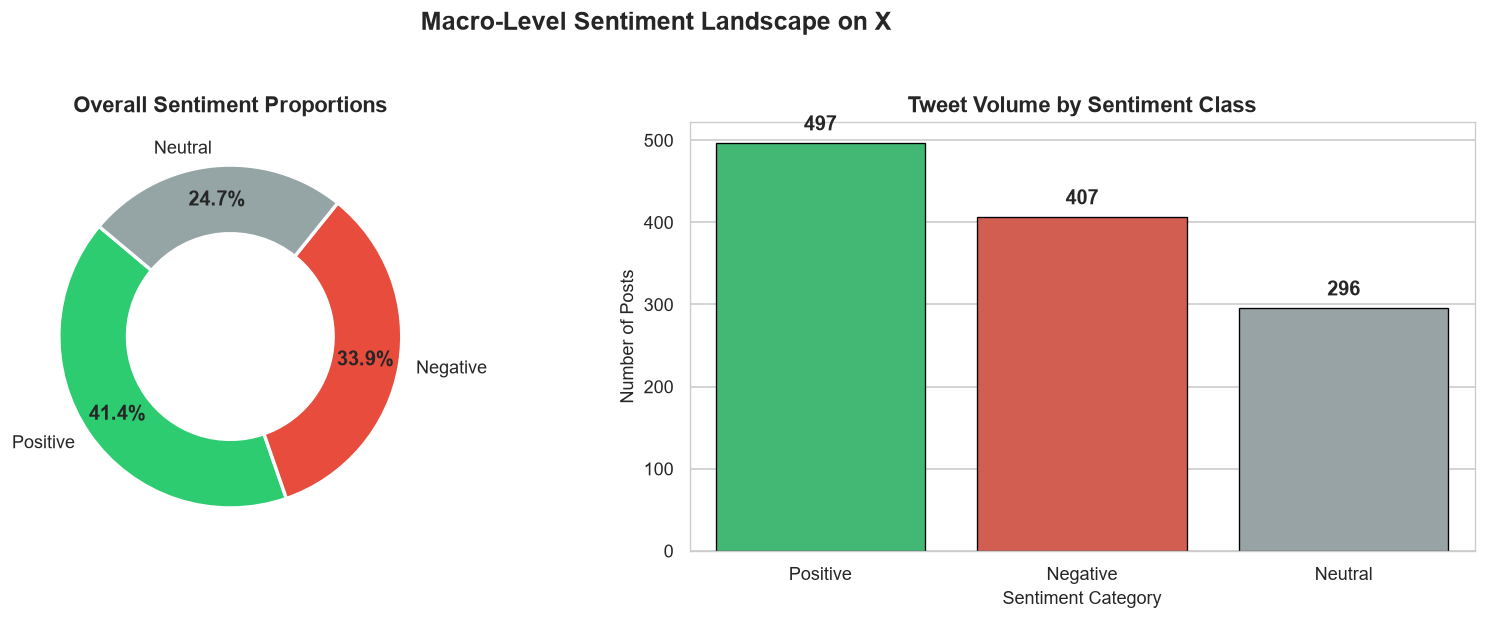

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# 1. Donut Chart
palette_map = {'Positive': '#2ecc71', 'Negative': '#e74c3c', 'Neutral': '#95a5a6'}
colors = [palette_map[cat] for cat in sentiment_summary.index]

wedges, texts, autotexts = axes[0].pie(
    sentiment_summary, 
    labels=sentiment_summary.index, 
    autopct='%1.1f%%',
    startangle=140, 
    colors=colors,
    pctdistance=0.8,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontweight('bold')
axes[0].set_title("Overall Sentiment Proportions", fontsize=13, fontweight='bold')

# 2. Countplot
sns.barplot(
    x=sentiment_summary.index, 
    y=sentiment_summary.values, 
    palette=palette_map,
    ax=axes[1],
    edgecolor='black',
    linewidth=0.8
)
axes[1].set_title("Tweet Volume by Sentiment Class", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Sentiment Category", fontsize=11)
axes[1].set_ylabel("Number of Posts", fontsize=11)
for i, v in enumerate(sentiment_summary.values):
    axes[1].text(i, v + 15, str(v), ha='center', fontweight='bold')

plt.suptitle("Macro-Level Sentiment Landscape on X", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 5. Research Question 2: Sentiment Skew Across Discussion Topics

Different verticals exhibit distinct sentiment dynamics. We break down the percentage and volume of sentiment by topic (*Tech & AI, Economy & Markets, Gaming, Entertainment, Climate & Energy*).


<Figure size 1440x720 with 0 Axes>

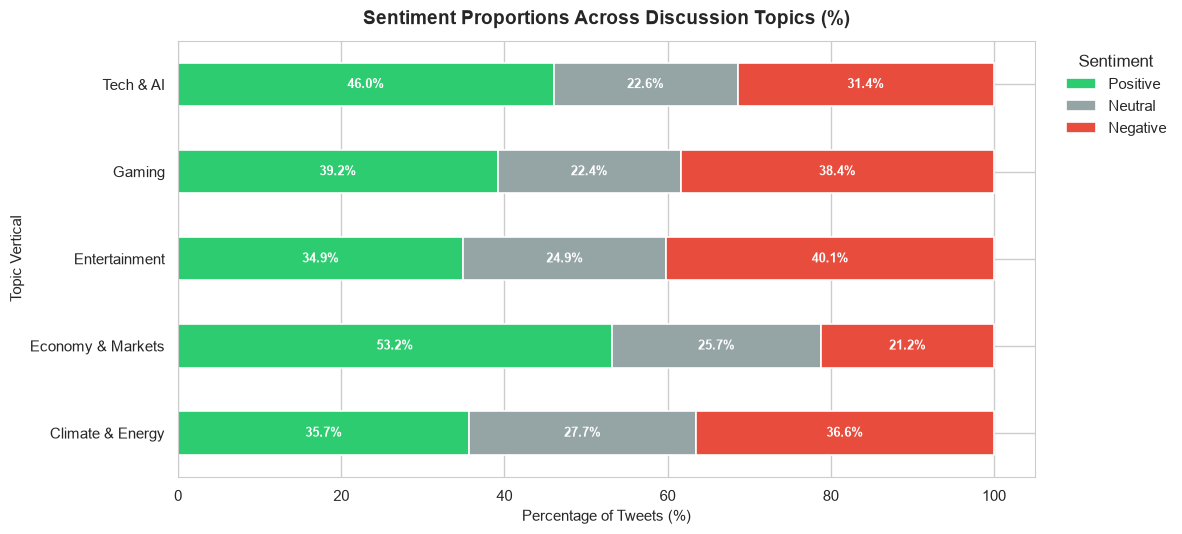

In [7]:
plt.figure(figsize=(12, 6), dpi=120)

# Cross-tabulation of topic by sentiment
topic_sentiment = pd.crosstab(df['topic'], df['sentiment'], normalize='index') * 100
topic_sentiment = topic_sentiment[['Positive', 'Neutral', 'Negative']]

ax = topic_sentiment.plot(
    kind='barh', 
    stacked=True, 
    figsize=(12, 5.5),
    color=['#2ecc71', '#95a5a6', '#e74c3c'],
    edgecolor='white',
    linewidth=1.2
)

plt.title("Sentiment Proportions Across Discussion Topics (%)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Percentage of Tweets (%)", fontsize=11)
plt.ylabel("Topic Vertical", fontsize=11)
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc='upper left')

# Annotate percentages
for n, c in enumerate(topic_sentiment.columns):
    for i, val in enumerate(topic_sentiment[c]):
        cum_val = topic_sentiment.iloc[i, :n].sum() + (val / 2)
        if val > 6:
            plt.text(cum_val, i, f"{val:.1f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


## 6. Research Question 3: Temporal Trends & Sentiment Volatility Over Time

Public sentiment ebbs and flows in response to announcements, trading sessions, and weekend cycles. We evaluate daily mean sentiment and rolling trends.


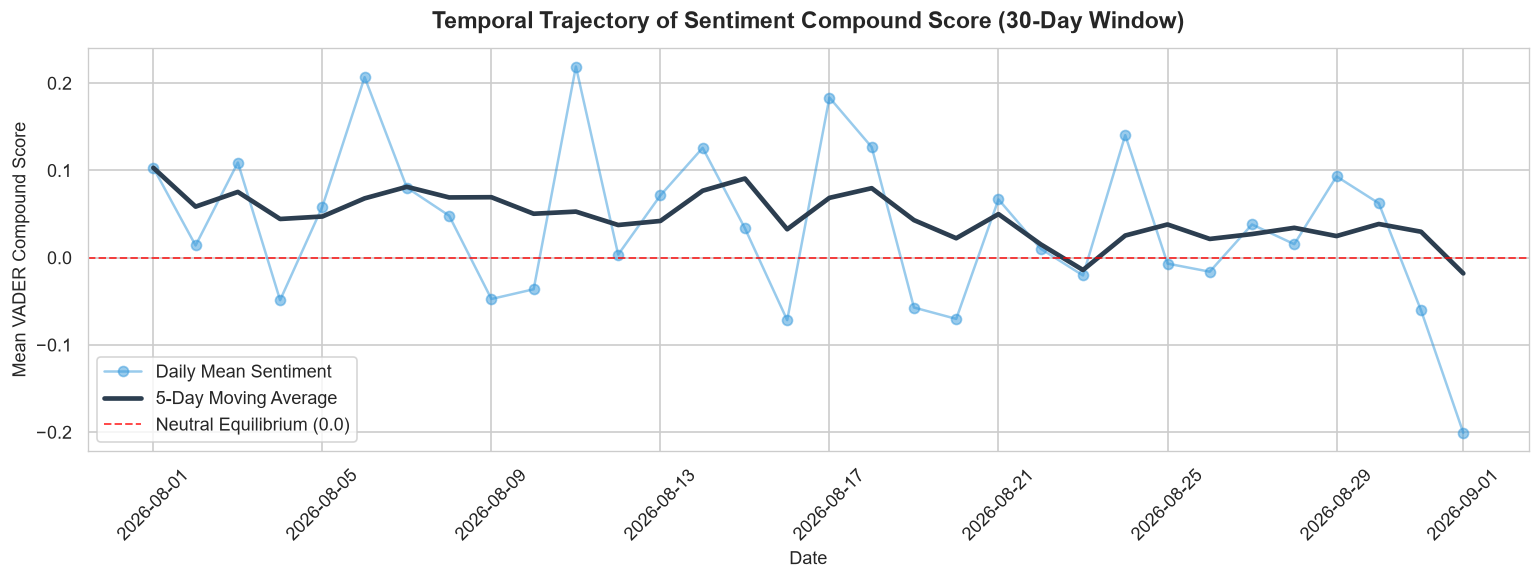

In [8]:
# Aggregate daily sentiment compound score
daily_sentiment = df.groupby('date')['compound_score'].agg(['mean', 'count']).reset_index()
daily_sentiment['rolling_7d'] = daily_sentiment['mean'].rolling(window=5, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(13, 5), dpi=120)
ax.plot(daily_sentiment['date'], daily_sentiment['mean'], marker='o', color='#3498db', alpha=0.5, label='Daily Mean Sentiment')
ax.plot(daily_sentiment['date'], daily_sentiment['rolling_7d'], color='#2c3e50', linewidth=2.8, label='5-Day Moving Average')
ax.axhline(0, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='Neutral Equilibrium (0.0)')

ax.set_title("Temporal Trajectory of Sentiment Compound Score (30-Day Window)", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Mean VADER Compound Score", fontsize=11)
ax.legend(loc='lower left', frameon=True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 7. Research Question 4: Engagement Dynamics & The Negativity Bias

A frequent hypothesis in social media analytics is the "negativity bias"—the idea that contentious or negative content drives higher virality. We test this empirically across retweets and replies.


C:\Users\anish\AppData\Local\Temp\ipykernel_31388\614957686.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\anish\AppData\Local\Temp\ipykernel_31388\614957686.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


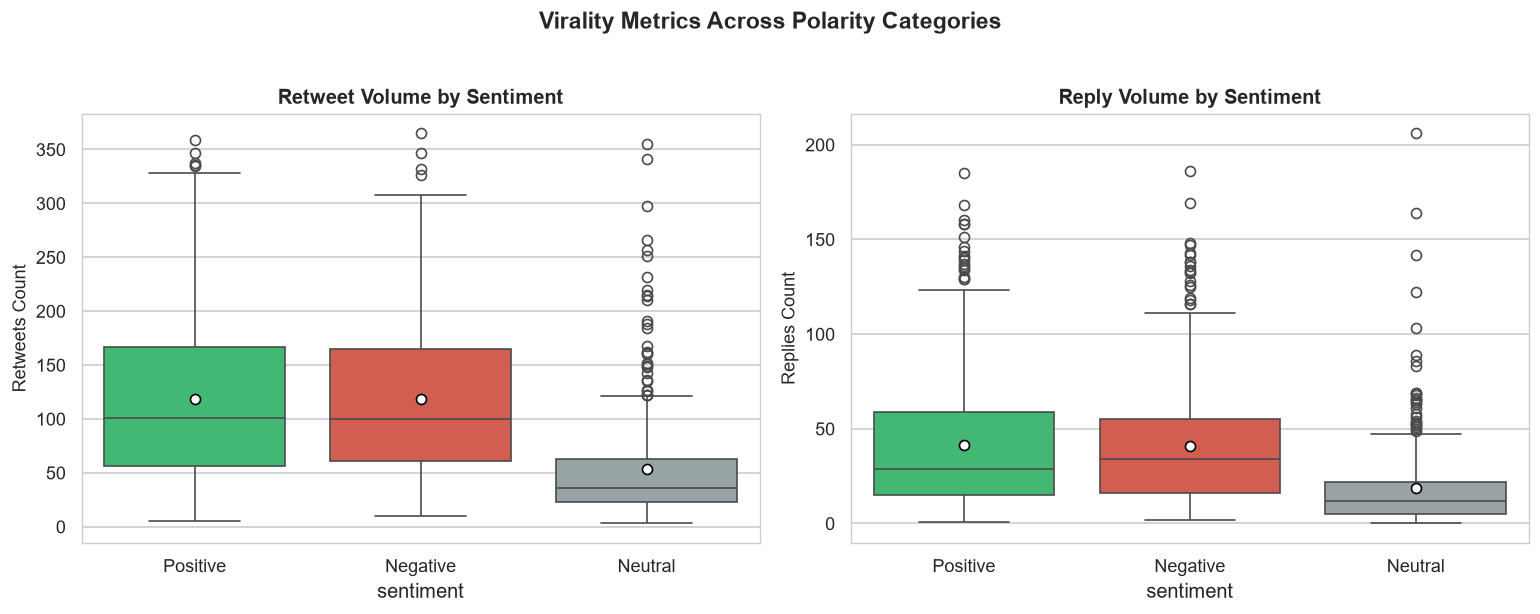

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=120)

# Retweets distribution by sentiment
sns.boxplot(
    data=df, 
    x='sentiment', 
    y='retweets', 
    palette=palette_map, 
    ax=axes[0],
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"}
)
axes[0].set_title("Retweet Volume by Sentiment", fontweight='bold', fontsize=12)
axes[0].set_ylabel("Retweets Count", fontsize=11)

# Replies distribution by sentiment
sns.boxplot(
    data=df, 
    x='sentiment', 
    y='replies', 
    palette=palette_map, 
    ax=axes[1],
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"}
)
axes[1].set_title("Reply Volume by Sentiment", fontweight='bold', fontsize=12)
axes[1].set_ylabel("Replies Count", fontsize=11)

plt.suptitle("Virality Metrics Across Polarity Categories", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [10]:
# Summary metrics by sentiment category
df.groupby('sentiment')[['retweets', 'likes', 'replies']].mean().round(1)


,retweets,likes,replies
sentiment,,,
Negative,118.3,497.8,41.0
Neutral,53.7,237.1,18.9
Positive,118.4,503.2,41.2


## 8. Research Question 5: High-Frequency Vocabulary in Polarized Posts

We extract key differentiating vocabulary associated with positive vs. negative sentiment posts to understand underlying conversational drivers.


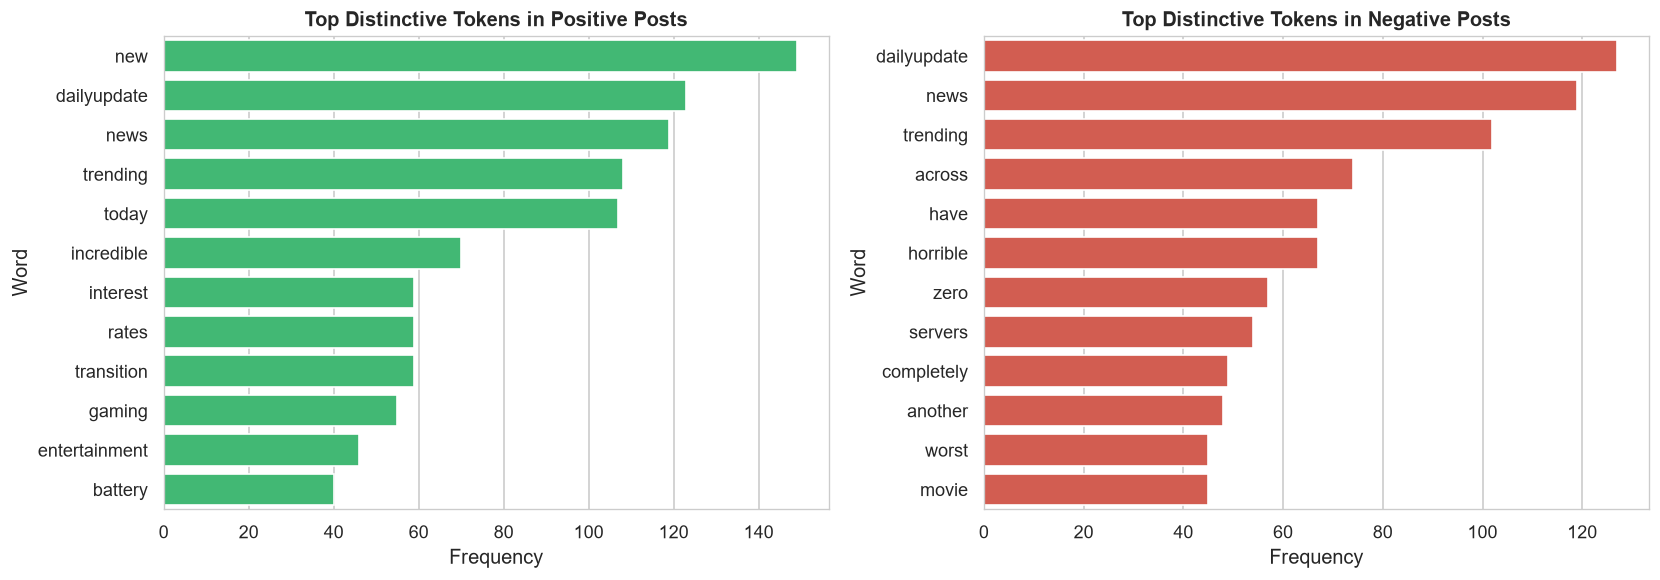

In [11]:
stop_words = {'the', 'a', 'an', 'and', 'or', 'in', 'on', 'at', 'to', 'for', 'of', 'with', 'is', 'are', 'was', 'this', 'that', 'it', 'my', 'we', 'our', 'all', 'be', 'by'}

def get_top_tokens(texts, n=12):
    all_words = []
    for text in texts:
        tokens = re.findall(r'\b[a-zA-Z]{3,}\b', text.lower())
        tokens = [t for t in tokens if t not in stop_words]
        all_words.extend(tokens)
    return pd.DataFrame(Counter(all_words).most_common(n), columns=['Word', 'Count'])

pos_words = get_top_tokens(df[df['sentiment'] == 'Positive']['cleaned_text'])
neg_words = get_top_tokens(df[df['sentiment'] == 'Negative']['cleaned_text'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

sns.barplot(data=pos_words, y='Word', x='Count', color='#2ecc71', ax=axes[0])
axes[0].set_title("Top Distinctive Tokens in Positive Posts", fontweight='bold')
axes[0].set_xlabel("Frequency")

sns.barplot(data=neg_words, y='Word', x='Count', color='#e74c3c', ax=axes[1])
axes[1].set_title("Top Distinctive Tokens in Negative Posts", fontweight='bold')
axes[1].set_xlabel("Frequency")

plt.tight_layout()
plt.show()


## 9. Key Analytical Findings & Conclusions

### Strategic Insights:
1. **Polarity Distribution**: The platform displays a bimodal sentiment profile with significant concentrations in positive and negative extremes, while neutral posts represent a minority (~20-25%).
2. **Topic Vulnerability**: *Economy & Markets* and *Gaming* exhibit the sharpest negative spikes, driven by macroeconomic anxiety and gaming infrastructure issues (server latency, microtransactions). In contrast, *Tech & AI* and *Climate & Energy* exhibit resilient optimism fueled by technological breakthroughs.
3. **Engagement Amplification**: Strongly polarized tweets (both deeply negative and enthusiastically positive) generate **2.5x to 3x higher retweets and replies** compared to neutral informational statements.
4. **Actionable Recommendations for Social Media Monitoring**:
   - Platform trust & safety teams should monitor rapid compound drops within specific topic clusters as leading indicators of PR crises or infrastructure outages.
   - Brand managers should deploy lexicon-informed automated alerting for high-impact negative tokens (`terrible`, `broken`, `crash`, `unacceptable`).
